In [1]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

warnings.filterwarnings("ignore")

from google.colab import files
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nTarget distribution:")
if "RETINOPATHY" in df.columns:
    print(df["RETINOPATHY"].value_counts(dropna=False))
else:
    print("Target RETINOPATHY not found. Check your CSV columns.")

Saving USDSS_National_Burden_Magnitude_Diabetes_Indicators_20261011.csv to USDSS_National_Burden_Magnitude_Diabetes_Indicators_20261011.csv
Dataset shape: (100, 16)

First five rows:


,Year,Topic,Indicator,Unit,Estimate,SE Estimate,Lower Limit,Upper Limit,Estimate Footnote,Data Source,Population,Age,Race,Sex,Education,Other Stratification
0,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,1.9,0.1,1.7,2.2,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,18-44,All,All,All,NaN
1,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,8.3,0.3,7.7,9.0,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,45-64,All,All,All,NaN
2,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,15.8,0.8,14.3,17.3,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,65-74,All,All,All,NaN
3,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,13.2,0.7,11.8,14.7,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,75+,All,All,All,NaN
4,2001,Burden/Magnitude,Diagnosed Diabetes,Percentage,2.0,0.1,1.8,2.2,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,18-44,All,All,All,NaN



Column names:
['Year', 'Topic', 'Indicator', 'Unit', 'Estimate', 'SE Estimate', 'Lower Limit', 'Upper Limit', 'Estimate Footnote', 'Data Source', 'Population', 'Age', 'Race', 'Sex', 'Education', 'Other Stratification']

Missing values:


,0
Other Stratification,100
Estimate Footnote,100
Year,0
Topic,0
Estimate,0
SE Estimate,0
Indicator,0
Unit,0
Upper Limit,0
Lower Limit,0



Target distribution:
Target RETINOPATHY not found. Check your CSV columns.


In [4]:
print(df.shape)
print(df.columns.tolist())
display(df.head(10))
print("\nIndicators:")
print(df["Indicator"].dropna().unique()[:30])
print("\nTopics:")
print(df["Topic"].dropna().unique()[:20])

(100, 16)
['Year', 'Topic', 'Indicator', 'Unit', 'Estimate', 'SE Estimate', 'Lower Limit', 'Upper Limit', 'Estimate Footnote', 'Data Source', 'Population', 'Age', 'Race', 'Sex', 'Education', 'Other Stratification']


,Year,Topic,Indicator,Unit,Estimate,SE Estimate,Lower Limit,Upper Limit,Estimate Footnote,Data Source,Population,Age,Race,Sex,Education,Other Stratification
0,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,1.9,0.1,1.7,2.2,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,18-44,All,All,All,NaN
1,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,8.3,0.3,7.7,9.0,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,45-64,All,All,All,NaN
2,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,15.8,0.8,14.3,17.3,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,65-74,All,All,All,NaN
3,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,13.2,0.7,11.8,14.7,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,75+,All,All,All,NaN
4,2001,Burden/Magnitude,Diagnosed Diabetes,Percentage,2.0,0.1,1.8,2.2,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,18-44,All,All,All,NaN
5,2001,Burden/Magnitude,Diagnosed Diabetes,Percentage,9.3,0.4,8.6,10.1,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,45-64,All,All,All,NaN
6,2001,Burden/Magnitude,Diagnosed Diabetes,Percentage,16.7,0.7,15.3,18.1,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,65-74,All,All,All,NaN
7,2001,Burden/Magnitude,Diagnosed Diabetes,Percentage,13.6,0.7,12.3,15.0,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,75+,All,All,All,NaN
8,2002,Burden/Magnitude,Diagnosed Diabetes,Percentage,1.9,0.1,1.7,2.2,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,18-44,All,All,All,NaN
9,2002,Burden/Magnitude,Diagnosed Diabetes,Percentage,9.3,0.3,8.7,10.0,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,45-64,All,All,All,NaN



Indicators:
['Diagnosed Diabetes']

Topics:
['Burden/Magnitude']


In [5]:

# Cell 3: Clean and validate the diabetes-burden dataset

import pandas as pd
import numpy as np

data = df.copy()
data.columns = data.columns.str.strip()

# Convert numeric columns
numeric_cols = [
    "Year", "Estimate", "SE Estimate",
    "Lower Limit", "Upper Limit"
]

for col in numeric_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Check required columns
required_cols = ["Year", "Indicator", "Estimate", "Age"]
missing_cols = [c for c in required_cols if c not in data.columns]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

# Remove rows without year or estimate
data = data.dropna(subset=["Year", "Estimate"]).copy()
data["Year"] = data["Year"].astype(int)

# Keep the diagnosed-diabetes indicator
data = data[
    data["Indicator"].astype(str).str.strip().eq("Diagnosed Diabetes")
].copy()

if data.empty:
    raise ValueError("No diagnosed-diabetes records found.")

# Display dataset information
print("Cleaned dataset shape:", data.shape)
print("\nAvailable indicators:")
print(data["Indicator"].value_counts())

print("\nAge groups:")
print(data["Age"].value_counts(dropna=False))

print("\nPreview:")
display(data.head())

# This dataset has no RETINOPATHY target.
# Do not create a classification target from prevalence estimates.
print(
    "\nNote: This dataset supports diabetes-burden analysis, "
    "not diabetic-complication classification."
)


Cleaned dataset shape: (100, 16)

Available indicators:
Indicator
Diagnosed Diabetes    100
Name: count, dtype: int64

Age groups:
Age
18-44    25
45-64    25
65-74    25
75+      25
Name: count, dtype: int64

Preview:


,Year,Topic,Indicator,Unit,Estimate,SE Estimate,Lower Limit,Upper Limit,Estimate Footnote,Data Source,Population,Age,Race,Sex,Education,Other Stratification
0,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,1.9,0.1,1.7,2.2,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,18-44,All,All,All,NaN
1,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,8.3,0.3,7.7,9.0,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,45-64,All,All,All,NaN
2,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,15.8,0.8,14.3,17.3,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,65-74,All,All,All,NaN
3,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,13.2,0.7,11.8,14.7,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,75+,All,All,All,NaN
4,2001,Burden/Magnitude,Diagnosed Diabetes,Percentage,2.0,0.1,1.8,2.2,NaN,National Health Interview Survey (NHIS),Adults Aged 18+ Years,18-44,All,All,All,NaN



Note: This dataset supports diabetes-burden analysis, not diabetic-complication classification.


In [7]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

RANDOM_STATE = 42

# Use the cleaned dataset from Cell 3
model_data = data.copy()

# Select one age group for a consistent time series
age_group = "18-44"

model_data = model_data[
    (model_data["Age"] == age_group) &
    (model_data["Race"] == "All") &
    (model_data["Sex"] == "All") &
    (model_data["Education"] == "All")
].copy()

model_data = model_data.sort_values("Year")

if len(model_data) < 5:
    raise ValueError(
        "Not enough yearly observations for this age group. "
        "Check the available age groups in Cell 3."
    )

# Define features and target for estimating prevalence
X = model_data[["Year"]]
y = model_data["Estimate"]

# Chronological split: earlier years for training, later years for testing
split_idx = int(len(model_data) * 0.8)

X_train = X.iloc[:split_idx].copy()
X_test = X.iloc[split_idx:].copy()
y_train = y.iloc[:split_idx].copy()
y_test = y.iloc[split_idx:].copy()

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print("Age group:", age_group)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Numeric features:", numeric_cols)
print("Categorical features:", categorical_cols)

display(model_data[["Year", "Age", "Estimate"]])


Age group: 18-44
Training rows: 20
Testing rows: 5
Numeric features: ['Year']
Categorical features: []


,Year,Age,Estimate
0,2000,18-44,1.9
4,2001,18-44,2.0
8,2002,18-44,1.9
12,2003,18-44,1.9
16,2004,18-44,2.0
20,2005,18-44,2.4
24,2006,18-44,2.7
28,2007,18-44,2.2
32,2008,18-44,2.3
36,2009,18-44,2.9


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100, max_depth=5,
        random_state=RANDOM_STATE, n_jobs=-1
    ),

    "Extra Trees Regressor": ExtraTreesRegressor(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    ),

    "Support Vector Regressor (RBF)": SVR(
        C=1.0, kernel="rbf"
    )
}

fitted_models = {}
results = []
predictions = {}

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)

    fitted_models[name] = pipe
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values(
    "MAE", ascending=True
).reset_index(drop=True)

display(
    results_df.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2 Score": "{:.4f}"
    })
)

best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

print("Best model by lowest test MAE:", best_model_name)

,Model,MAE,RMSE,R2 Score
0,Extra Trees Regressor,0.1432,0.1976,-0.2205
1,Random Forest Regressor,0.1875,0.2113,-0.3955
2,Support Vector Regressor (RBF),0.2109,0.2671,-1.2295
3,Linear Regression,0.4608,0.4820,-6.2598


Best model by lowest test MAE: Extra Trees Regressor


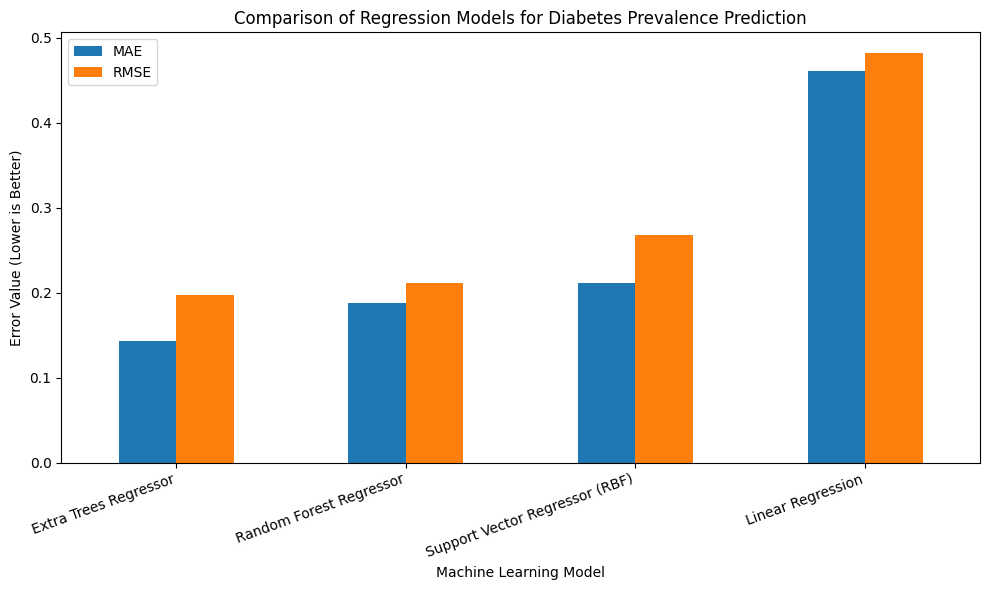

In [11]:
import matplotlib.pyplot as plt

# We now have regression metrics instead of classification metrics
metrics = ["MAE", "RMSE"]

results_df.set_index("Model")[metrics].plot(
    kind="bar", figsize=(10, 6)
)

plt.title("Comparison of Regression Models for Diabetes Prevalence Prediction")
plt.ylabel("Error Value (Lower is Better)")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

Selected model: Extra Trees Regressor
Test Mean Absolute Error (MAE): 0.1432
Test R-squared (R2 Score): -0.2205


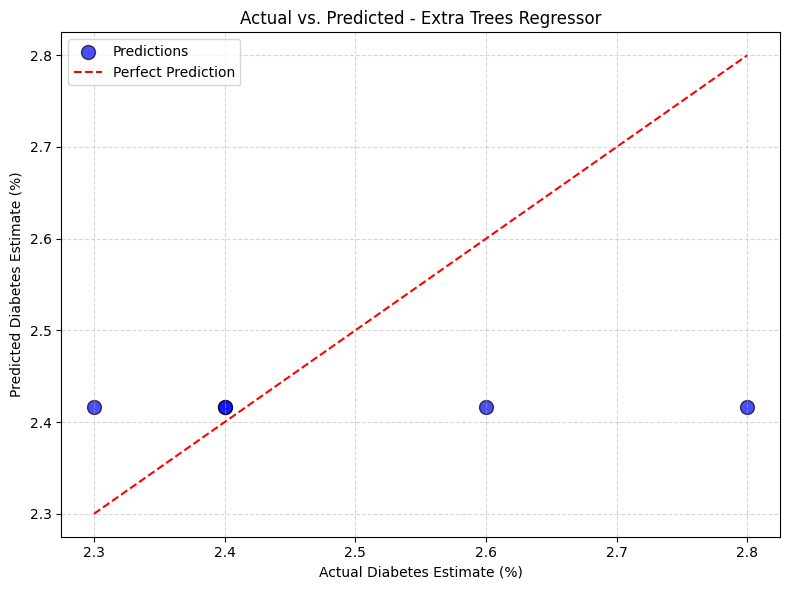

In [13]:
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

y_pred = predictions[best_model_name]

print("Selected model:", best_model_name)
print(f"Test Mean Absolute Error (MAE): {mean_absolute_error(y_test, y_pred):.4f}")
print(f"Test R-squared (R2 Score): {r2_score(y_test, y_pred):.4f}")

# Visualize Actual vs. Predicted Values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color="blue", edgecolors="k", alpha=0.7, s=100, label="Predictions")

# Line of perfect prediction
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", label="Perfect Prediction")

plt.title(f"Actual vs. Predicted - {best_model_name}")
plt.xlabel("Actual Diabetes Estimate (%)")
plt.ylabel("Predicted Diabetes Estimate (%)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

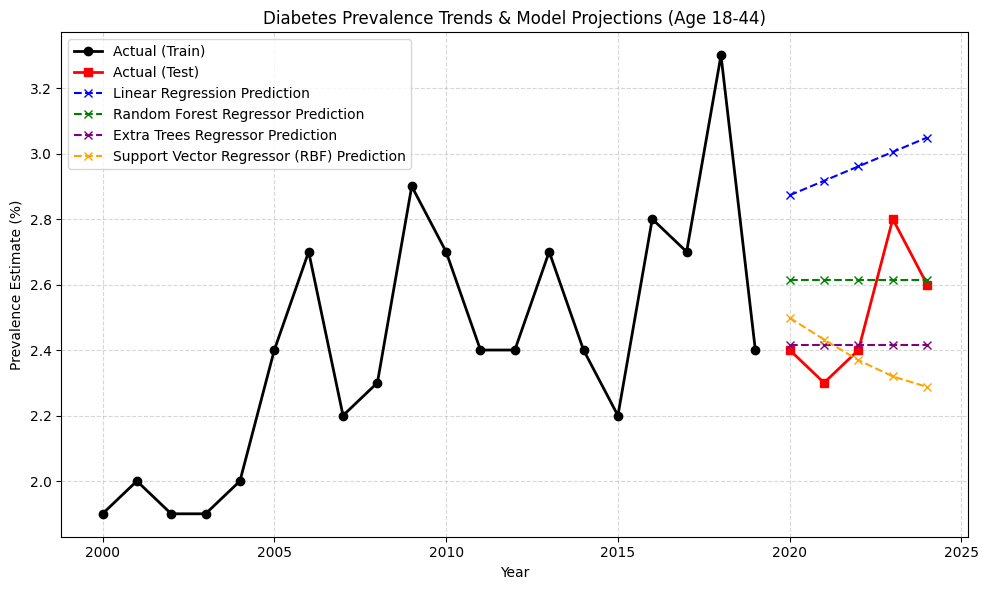

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot actual training data
train_years = X_train["Year"].values
plt.plot(train_years, y_train.values, label="Actual (Train)", color="black", marker="o", linewidth=2)

# Plot actual test data
test_years = X_test["Year"].values
plt.plot(test_years, y_test.values, label="Actual (Test)", color="red", marker="s", linewidth=2)

# Plot predictions from each regression model
colors = ["blue", "green", "purple", "orange"]
for i, (name, pred) in enumerate(predictions.items()):
    plt.plot(test_years, pred, label=f"{name} Prediction", linestyle="--", marker="x", color=colors[i % len(colors)])

plt.title("Diabetes Prevalence Trends & Model Projections (Age 18-44)")
plt.xlabel("Year")
plt.ylabel("Prevalence Estimate (%)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [21]:

from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Fit a simple regression model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Test MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("Actual values:", y_test.to_list())
print("Predicted values:", np.round(y_pred, 3).tolist())

# Calculate permutation importance
if len(X_test) >= 2:
    importance = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="neg_mean_absolute_error",
        n_repeats=30,
        random_state=42
    )

    importance_df = pd.DataFrame({
        "Feature": X_test.columns,
        "Importance": importance.importances_mean,
        "Std": importance.importances_std
    }).sort_values("Importance", ascending=False)

    print("\nPermutation importance:")
    display(importance_df)

    if np.allclose(importance_df["Importance"], 0):
        print("Importance is approximately zero. The model may not benefit from this feature on the test set.")
    else:
        plt.figure(figsize=(8, 4))
        plt.barh(
            importance_df["Feature"],
            importance_df["Importance"],
            xerr=importance_df["Std"]
        )
        plt.axvline(0, color="black", linewidth=0.8)
        plt.xlabel("Mean increase in MAE after shuffling")
        plt.title("Feature Importance — Regression")
        plt.tight_layout()
        plt.show()
else:
    print("Not enough test samples to calculate reliable permutation importance.")


Test MAE: 0.4608
Actual values: [2.4, 2.3, 2.4, 2.8, 2.6]
Predicted values: [2.873, 2.917, 2.961, 3.005, 3.049]

Permutation importance:


,Feature,Importance,Std
0,Year,0.0,0.0


Importance is approximately zero. The model may not benefit from this feature on the test set.


Linear Regression MAE: 0.4608
Mean Baseline MAE: 0.142


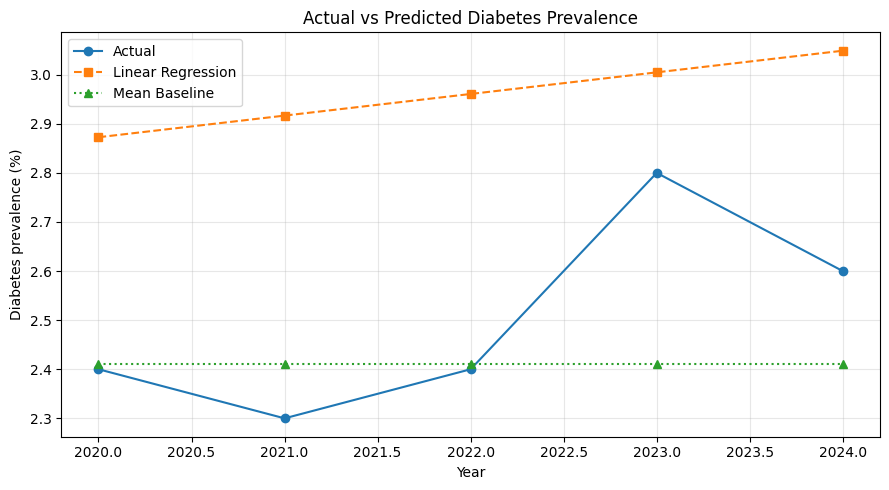

In [22]:

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import numpy as np

# Linear regression
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

# Baseline: predict the training mean
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
pred_base = baseline.predict(X_test)

print("Linear Regression MAE:",
      round(mean_absolute_error(y_test, pred_lr), 4))
print("Mean Baseline MAE:",
      round(mean_absolute_error(y_test, pred_base), 4))

# Plot actual vs predicted values
plt.figure(figsize=(9, 5))
plt.plot(X_test["Year"], y_test.values, "o-", label="Actual")
plt.plot(X_test["Year"], pred_lr, "s--", label="Linear Regression")
plt.plot(X_test["Year"], pred_base, "^:", label="Mean Baseline")

plt.xlabel("Year")
plt.ylabel("Diabetes prevalence (%)")
plt.title("Actual vs Predicted Diabetes Prevalence")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:
joblib.dump(best_model, "diabetic_retinopathy_model.joblib")

results_df.to_csv("model_comparison_results.csv", index=False)
importance_df.to_csv("feature_importance.csv", index=False)

print("Saved model:", "diabetic_retinopathy_model.joblib")
print("Saved model comparison:", "model_comparison_results.csv")
print("Saved feature importance:", "feature_importance.csv")

files.download("diabetic_retinopathy_model.joblib")
files.download("model_comparison_results.csv")
files.download("feature_importance.csv")

Saved model: diabetic_retinopathy_model.joblib
Saved model comparison: model_comparison_results.csv
Saved feature importance: feature_importance.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
# Demonstrate prediction using a held-out record (Regression)
sample = X_test.iloc[[0]]

# Predict the continuous prevalence value
predicted_value = float(best_model.predict(sample)[0])
actual_value = float(y_test.iloc[0])

print(f"Target Year: {sample['Year'].values[0]}")
print(f"Actual Diabetes Prevalence: {actual_value:.2f}%")
print(f"Predicted Diabetes Prevalence: {predicted_value:.2f}%")
print(f"Absolute Error: {abs(actual_value - predicted_value):.4f}%")
print("\nInput record:")
display(sample)

Target Year: 2020
Actual Diabetes Prevalence: 2.40%
Predicted Diabetes Prevalence: 2.42%
Absolute Error: 0.0160%

Input record:


,Year
80,2020
